In [5]:
# Cell 1 — Import
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

In [23]:
CONFIG = {
    "img_size"    : (224, 224),
    "batch_size"  : 32,
    "epochs"      : 10,
    "learning_rate": 0.001,
    "train_dir"   : "../data/train",
    "val_dir"     : "../data/val",
    "model_path"  : "../outputs/models/best_model.keras"
}

In [11]:
train_datagen = ImageDataGenerator(
    rescale=1./255,           
    horizontal_flip=True,     # พลิกซ้าย-ขวา
    rotation_range=15,        # หมุน ±15 องศา
    zoom_range=0.2,           # ซูมสุ่ม
    width_shift_range=0.1,    # เลื่อนซ้าย-ขวา
    height_shift_range=0.1    # เลื่อนบน-ล่าง
)

val_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    CONFIG["train_dir"],
    target_size=CONFIG["img_size"],
    batch_size=CONFIG["batch_size"],
    class_mode='binary',
    shuffle=True
)

val_gen = val_datagen.flow_from_directory(
    CONFIG["val_dir"],
    target_size=CONFIG["img_size"],
    batch_size=CONFIG["batch_size"],
    class_mode='binary',
    shuffle=False
)

print("Class indices:", train_gen.class_indices)

Found 3001 images belonging to 2 classes.


Found 1000 images belonging to 2 classes.
Class indices: {'cat': 0, 'dog': 1}


In [12]:
def build_model(learning_rate):
    base_model = MobileNetV2(
        input_shape=(*CONFIG["img_size"], 3),
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False  

    inputs = tf.keras.Input(shape=(*CONFIG["img_size"], 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)  
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)            
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = tf.keras.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model, base_model

model, base_model = build_model(CONFIG["learning_rate"])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [13]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [14]:
os.makedirs("outputs/models", exist_ok=True)

callbacks = [

    ModelCheckpoint(
        CONFIG["model_path"],
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,       
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

In [16]:
print("เทรน แบบ freeze")

history_phase1 = model.fit(
    train_gen,
    epochs=CONFIG["epochs"],
    validation_data=val_gen,
    callbacks=callbacks,
    verbose=1
)

เทรน แบบ freeze
Epoch 1/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 338ms/step - accuracy: 0.9892 - loss: 0.0386
Epoch 1: val_accuracy did not improve from 0.98100
94/94 ━━━━━━━━━━━━━━━━━━━━ 39s 417ms/step - accuracy: 0.9857 - loss: 0.0441 - val_accuracy: 0.9780 - val_loss: 0.0533 - learning_rate: 5.0000e-04
Epoch 2/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 345ms/step - accuracy: 0.9844 - loss: 0.0389
Epoch 2: val_accuracy improved from 0.98100 to 0.98200, saving model to outputs/models/best_model.keras

Epoch 2: finished saving model to outputs/models/best_model.keras
94/94 ━━━━━━━━━━━━━━━━━━━━ 40s 425ms/step - accuracy: 0.9843 - loss: 0.0401 - val_accuracy: 0.9820 - val_loss: 0.0497 - learning_rate: 5.0000e-04
Epoch 3/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 335ms/step - accuracy: 0.9889 - loss: 0.0253
Epoch 3: val_accuracy did not improve from 0.98200
94/94 ━━━━━━━━━━━━━━━━━━━━ 38s 409ms/step - accuracy: 0.9883 - loss: 0.0291 - val_accuracy: 0.9820 - val_loss: 0.0502 - learning_rate: 5.0000e-04
Epoch 4/10
94/9

In [17]:
# ลองเเบบ unfreeze บางส่วน

base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [19]:

history_phase2 = model.fit(
    train_gen,
    epochs=10,
    validation_data=val_gen,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 384ms/step - accuracy: 0.9649 - loss: 0.0912
Epoch 1: val_accuracy did not improve from 0.98200
94/94 ━━━━━━━━━━━━━━━━━━━━ 43s 455ms/step - accuracy: 0.9623 - loss: 0.0969 - val_accuracy: 0.9780 - val_loss: 0.0601 - learning_rate: 5.0000e-06
Epoch 2/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 364ms/step - accuracy: 0.9595 - loss: 0.1069
Epoch 2: val_accuracy did not improve from 0.98200
94/94 ━━━━━━━━━━━━━━━━━━━━ 41s 433ms/step - accuracy: 0.9663 - loss: 0.0873 - val_accuracy: 0.9790 - val_loss: 0.0564 - learning_rate: 5.0000e-06
Epoch 3/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 361ms/step - accuracy: 0.9645 - loss: 0.0865
Epoch 3: val_accuracy did not improve from 0.98200

Epoch 3: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-06.
94/94 ━━━━━━━━━━━━━━━━━━━━ 41s 432ms/step - accuracy: 0.9670 - loss: 0.0849 - val_accuracy: 0.9790 - val_loss: 0.0559 - learning_rate: 5.0000e-06
Epoch 4/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 363ms/step - accuracy: 0.9740 - l

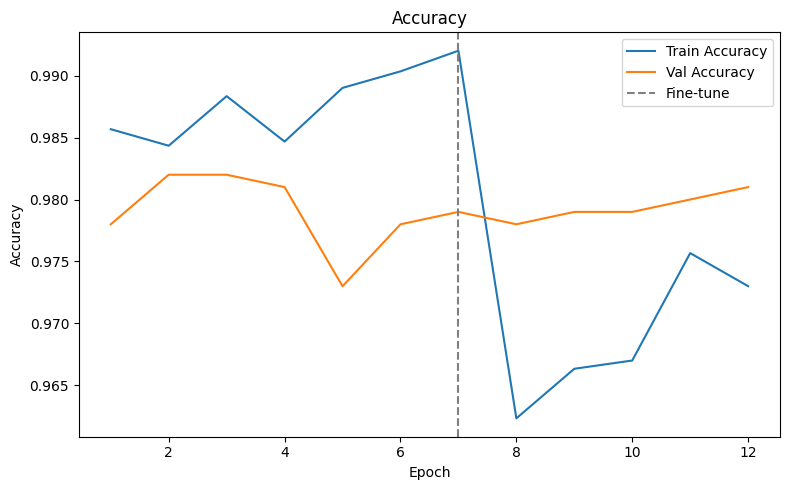

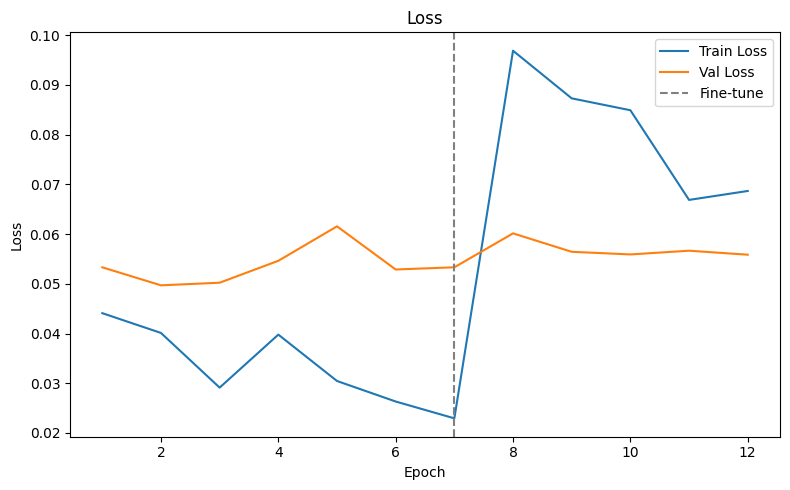

finish


In [21]:
def plot_history(h1, h2, save_dir="../outputs/plots"):
    os.makedirs(save_dir, exist_ok=True)

    acc     = h1.history['accuracy']     + h2.history['accuracy']
    val_acc = h1.history['val_accuracy'] + h2.history['val_accuracy']
    loss    = h1.history['loss']         + h2.history['loss']
    val_loss= h1.history['val_loss']     + h2.history['val_loss']

    epochs  = range(1, len(acc) + 1)
    split   = len(h1.history['accuracy']) 

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, acc,     label='Train Accuracy')
    plt.plot(epochs, val_acc, label='Val Accuracy')
    plt.axvline(x=split, color='gray', linestyle='--', label='Fine-tune')
    plt.title('Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{save_dir}/accuracy.png")
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, loss,     label='Train Loss')
    plt.plot(epochs, val_loss, label='Val Loss')
    plt.axvline(x=split, color='gray', linestyle='--', label='Fine-tune')
    plt.title('Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{save_dir}/loss.png")
    plt.show()

    print("finish")

plot_history(history_phase1, history_phase2)

In [25]:
loss, acc = model.evaluate(val_gen, verbose=0)
print(f"\n Validation Set")
print(f"   Loss     : {loss:.4f}")
print(f"   Accuracy : {acc:.2%}")


 Validation Set
   Loss     : 0.0601
   Accuracy : 97.80%


In [26]:
model.save("../outputs/models/best_model.keras")

In [27]:
model.save("../outputs/models/best_model.h5")